# TF-IDF + Logistic Regression

As a baseline model, we use a Term Frequency-Inverse Document Frequency representation
combined with a Random Forest classifier.

TF-IDF is a numerical statistic used in information retrieval and machine learning to

#1. Importing requirements

In [1]:
#Import requirements
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import pandas as pd
import numpy as np
import csv



#2. Cleaning and preparing raw data

In [2]:
#Path of the files
file_path = "/content/data.csv"
df = pd.read_csv(file_path)

#Remove special simbols
import re

def clean_text(text):

    text = text.lower()
    text = re.sub(r"[^a-zA-Z\s]", " ", text)
    text = re.sub(r"\s+", " ", text)

    return text

df["clean_text"] = (df["title"] + " " + df["text"]).apply(clean_text)

#Remove stopwords
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
all_words = " ".join(df["clean_text"]).split()
stopwords = set(ENGLISH_STOP_WORDS)
filtered_words = [
    word for word in all_words
    if word not in stopwords and len(word) > 2
]



#3. Tokenize and vectorize data

In [3]:
import nltk
nltk.download(['punkt_tab', 'wordnet', 'omw-1.4', 'averaged_perceptron_tagger', 'universal_tagset'], quiet=True)
nltk.download('averaged_perceptron_tagger_eng', quiet=True)


True

In [4]:

from nltk.tokenize import word_tokenize
from nltk.stem.wordnet import WordNetLemmatizer
from nltk.corpus import wordnet
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences


# 1. Tokenization(NLTK)
tokenized = [word_tokenize(doc.lower()) for doc in filtered_words]

# 2. Lematization
lemmatizer = WordNetLemmatizer()

def get_wordnet_pos(tag):
    """Converts an NLTK tag to WordNet format"""
    return {'J': wordnet.ADJ, 'N': wordnet.NOUN,
            'V': wordnet.VERB, 'R': wordnet.ADV}.get(tag[0], wordnet.NOUN)

def lemmatize_document(doc):
    """Lemmatize a whole doc (faster)"""
    tagged = nltk.pos_tag(doc)             #branding all document
    lemmatized = []
    for word, tag in tagged:
        pos = get_wordnet_pos(tag)
        lemma = lemmatizer.lemmatize(word, pos)
        lemmatized.append(lemma)
    return lemmatized

# Aply lemmatization
lemma_words = [lemmatize_document(doc) for doc in tokenized]

print(" Lemmatization complete. Examples:")
print(lemma_words[0][:15])

# 3. Reconstruct clean test for Keras
cleaned_texts = [' '.join(doc) for doc in lemma_words]

# 4. Numeric tokenazation (Keras)
tokenizer = Tokenizer(oov_token='<OOV>')
tokenizer.fit_on_texts(cleaned_texts)
sequences = tokenizer.texts_to_sequences(cleaned_texts)
#Padding the inputs for the model in order to have same lenght
max_seq_len = max(len(seq) for seq in sequences)
padded = pad_sequences(sequences, maxlen=max_seq_len, padding='pre')

print(f"\n Padding ended. Final shape: {padded.shape}")


 Lemmatization complete. Examples:
['budget']

 Padding ended. Final shape: (8588931, 2)


#4. Building, training model and evaluation

In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import pandas as pd
import numpy as np

# === 3. TF-IDF (the most important part) ===
tfidf = TfidfVectorizer(
    max_features=10000,      # adjust to your vocabulary (5000-20000)
    ngram_range=(1, 2),      # unigrams + bigrams (improves the result a lot)
    min_df=2,                # ignore words that appear in fewer than 2 docs
    max_df=0.95,             # ignore words that appear in more than 95% of docs
    stop_words='english'  # change if the text is in Spanish
)

X = tfidf.fit_transform((df["clean_text"]))
y=df["label"]
print(f"✅ Matriz TF-IDF creada: {X.shape} (documentos x palabras)")

# === 4. DIVIDIR TRAIN / TEST ===
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# === 5. ENTRENAR Random Forest ===
rf_model = RandomForestClassifier(
    n_estimators=200,      # more trees = better (but slower)
    max_depth=None,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1              # use all CPU cores
)

rf_model.fit(X_train, y_train)

# === 6. PREDICCIONES Y RESULTADOS ===
y_pred = rf_model.predict(X_test)

print("=== RESULTADOS DEL MODELO ===")
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))



✅ Matriz TF-IDF creada: (39942, 10000) (documentos x palabras)
=== RESULTADOS DEL MODELO ===
Accuracy: 0.9989

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      3989
           1       1.00      1.00      1.00      4000

    accuracy                           1.00      7989
   macro avg       1.00      1.00      1.00      7989
weighted avg       1.00      1.00      1.00      7989



#5. Graphics

/tmp/ipykernel_200/2814046022.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


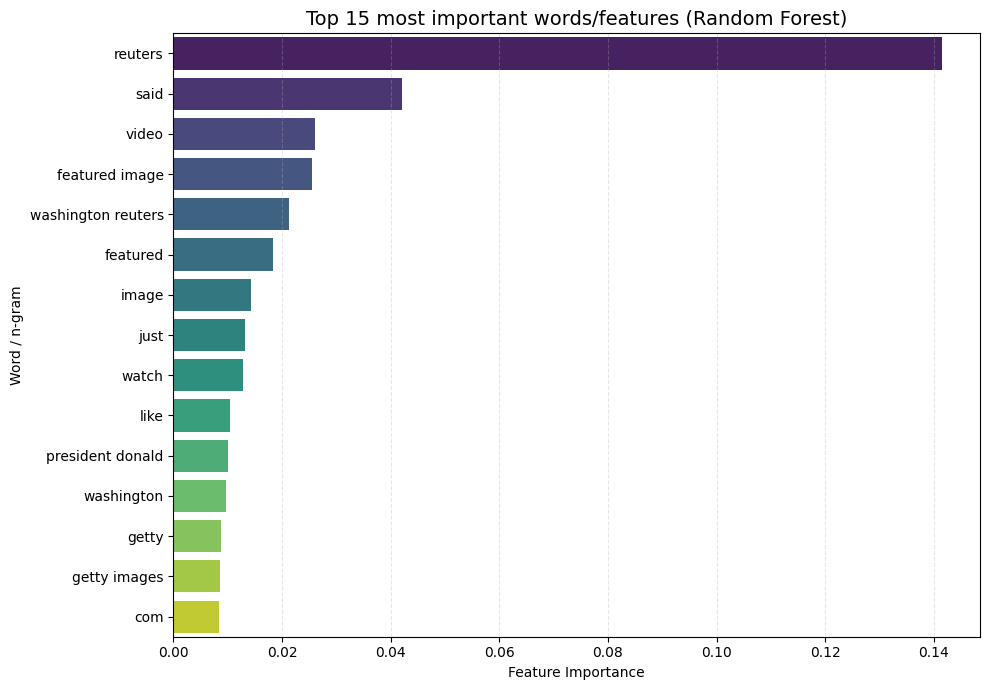

In [10]:
#  Top importance words by random forest
#Only predicted importance not correlation to label FAKE or REAl

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Name of words
feature_names = tfidf.get_feature_names_out()

# Importance
importances = rf_model.feature_importances_
top_n = 15

# Index by importance
top_idx = np.argsort(importances)[-top_n:][::-1]

top_features = feature_names[top_idx]
top_importance = importances[top_idx]

df_importance = pd.DataFrame({
    'word': top_features,
    'importance': top_importance
})

# Graphic
plt.figure(figsize=(10, 7))
sns.barplot(
    data=df_importance,
    x='importance',
    y='word',
    palette='viridis'
)

plt.title('Top 15 most important words/features (Random Forest)', fontsize=14)
plt.xlabel('Feature Importance')
plt.ylabel('Word / n-gram')
plt.grid(axis='x', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

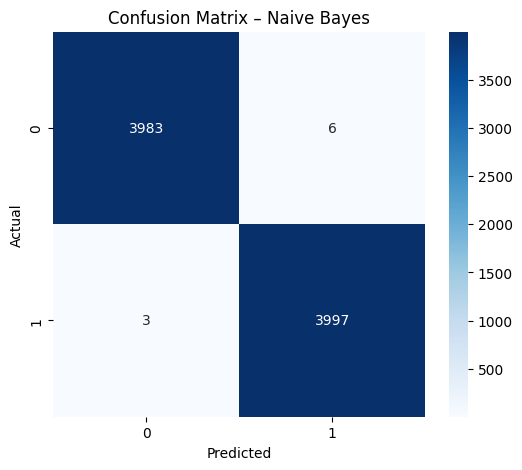

In [7]:
#Confusion Matrix
import matplotlib.pyplot as plt
import seaborn as sns
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix – Naive Bayes")

plt.show()
